# SEI Research

Отдельный ноутбук для исследования Signed Entropy Integral (SEI)

поскольку в основном ноутбуке много ячеек,

я решил сделать отдельный более удобный, компактный ноутбук для дальнейшего исследования sei метода

## Импорты и настройки

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    precision_recall_curve,
)
from cleanlab.rank import get_label_quality_scores

# Импорты из src
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Не найдена src")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import SimpleCNN, FashionCNN, count_trainable_parameters
from src.data import load_small_dataset
from src.training import train_one_epoch, predict, measure_cnn_quality, train_and_measure
from src.utils import set_seed, get_device

#константы
SEED = 42
DATASET_NAME = "FashionMNIST"  # MNIST или FashionMNIST
TRAIN_LIMIT = 50000
TEST_LIMIT = None
NOISE_TYPE = "symmetric" #"symmetric"  #"class_dependent", "instance_dependent"
NOISE_RATE = 0.20       #доля меток, которые испортим
FOLDS = 3              #для кросс-валидации
ENSEMBLE_SIZE = 3
EPOCHS = 50
OOF_EPOCHS = 50
BATCH_SIZE = 128
K_NEIGHBORS = 10
CNN_QUALITY_EPOCHS = 100
CNN_QUALITY_SEEDS = [SEED]
CLEANING_REPEAT_SEEDS = [SEED]
CLEANING_FINAL_EPOCHS = 50

# Переключатели oof методов(false, поскольку сейчас фокус на энтропию) 
RUN_LEGACY_OOF = False              # этапы 3-7 и сравнение с OOF/Cleanlab/3 сигналами
RUN_LEGACY_CLEANING = False         # этапы 7 и 9; требуют OOF-результатов
RUN_CLASSIFIER_COMPARISONS = False  # этап 1.1 и этап 10; отдельные долгие обучения CNN
RUN_CIFAR10N = False                # старый OOF-эксперимент на CIFAR-10N
RUN_SEI_CIFAR10N = True           # отдельная проверка SEI на CIFAR-10N (без OOF)

REQUIRE_CUDA = True
DEVICE = get_device(require_cuda=REQUIRE_CUDA)
if DEVICE.type == "cuda":
    print("Устройство:", torch.cuda.get_device_name(0))
    print("Версия CUDA в PyTorch:", torch.version.cuda)
else:
    print("Устройство:", DEVICE)

DATA_ROOT = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "results_vkr"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

set_seed()

Устройство: NVIDIA GeForce RTX 3060 Laptop GPU
Версия CUDA в PyTorch: 13.2


c:\Users\aptem\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Загрузка Fashion-MNIST / MNIST

In [2]:
X_train, y_true, X_test, y_test = load_small_dataset(
    DATASET_NAME, TRAIN_LIMIT, TEST_LIMIT, data_root=DATA_ROOT, seed=SEED
)
NUM_CLASSES = 10
print("Датасет:", DATASET_NAME)
print("Размер обучающей выборки:", len(y_true))
print("Размер тестовой выборки:", len(y_test))


Датасет: FashionMNIST
Размер обучающей выборки: 50000
Размер тестовой выборки: 10000


## Генерация искусственного шума для SEI

In [3]:
#ИСКУССТВЕННЫЙ ШУМ
def make_noisy_labels(X, y, noise_type, noise_rate, seed=SEED):
    """Меняет заданную долю меток и возвращает их плюс маску ошибок."""
    rng = np.random.default_rng(seed)
    y_original = y.cpu().numpy().copy()
    y_noisy = y_original.copy()
    n_classes = len(np.unique(y_original))
    n_errors = int(round(len(y_original) * noise_rate))

    if noise_type == "instance_dependent":
        variation = X.flatten(1).std(dim=1).cpu().numpy()
        weights = 1.0 / (variation + 0.05)
        weights = weights / weights.sum()
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False, p=weights)
    else:
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False)

    if noise_type == "class_dependent":
        y_noisy[bad_ids] = (y_original[bad_ids] + 1) % n_classes

    elif noise_type in ("symmetric", "instance_dependent"):
        new_labels = rng.integers(0, n_classes, size=n_errors)
        same = new_labels == y_original[bad_ids]
        while same.any():
            new_labels[same] = rng.integers(0, n_classes, size=same.sum())
            same = new_labels == y_original[bad_ids]
        y_noisy[bad_ids] = new_labels

    else:
        raise ValueError("Неизвестный тип шума")

    noise_mask = y_noisy != y_original
    return torch.tensor(y_noisy, dtype=torch.long), noise_mask


y_noisy, noise_mask = make_noisy_labels(X_train, y_true, NOISE_TYPE, NOISE_RATE)
print("Тип шума:", NOISE_TYPE)
print("Заданный уровень шума:", NOISE_RATE)
print("Фактически испорчено меток:", int(noise_mask.sum()), "из", len(noise_mask))

Тип шума: symmetric
Заданный уровень шума: 0.2
Фактически испорчено меток: 10000 из 50000


## Вспомогательная функция оценки рейтинга подозрительности

In [4]:
def evaluate_score(name, score, bad_mask):
    bad_mask = np.asarray(bad_mask).astype(int)
    score = np.asarray(score)
    k = max(1, int(bad_mask.sum()))  # K берётся из числа реальных ошибок только для оценки
    top_ids = np.argsort(score)[::-1][:k]
    return {
        "Метод": name,
        "Precision@K": bad_mask[top_ids].mean(),
        "Average Precision": average_precision_score(bad_mask, score), 
        "ROC-AUC": roc_auc_score(bad_mask, score) if len(np.unique(bad_mask)) > 1 else np.nan,
        }

'''
 #Чем выше Precision@K, тем меньше правильных меток ошибочно отнесли к подозрительным при таком размере списка
 #Высокий AP = испорченные метки в целом оказываются ближе к началу списка подозрительности
 #ROC-AUC способность рейтинга отделять испорченные метки от правильных при рассмотрении разных порогов
'''

'\n #Чем выше Precision@K, тем меньше правильных меток ошибочно отнесли к подозрительным при таком размере списка\n #Высокий AP = испорченные метки в целом оказываются ближе к началу списка подозрительности\n #ROC-AUC способность рейтинга отделять испорченные метки от правильных при рассмотрении разных порогов\n'

## Этап 6. Проверка на реальном шуме CIFAR-10N

 Для запуска нужен `CIFAR-10_human.pt`, он лежит в репозитории: https://github.com/UCSC-REAL/cifar-10-100n
 
Протокол использует человеческие метки как шумные, а `clean_label` из бенчмарка как опорный вариант для оценки.

## Настройки CIFAR-10N для отдельной проверки SEI

In [5]:
#Настройки для 6 этапа
RUN_CIFAR10N = True
CIFAR10N_LABEL_TYPE = "aggre_label"  # aggre_label, random_label1/2/3, worse_label
CIFAR10N_TRAIN_LIMIT = TRAIN_LIMIT
CIFAR10N_TEST_LIMIT = 1000
CIFAR10N_FOLDS = 3
CIFAR10N_ENSEMBLE_SIZE = 2
CIFAR10N_EPOCHS = OOF_EPOCHS

#7 этап работает как на данных 1-5 этапов, так и на данных 6 этапа, эпохи можно увеличить
CLEANING_EPOCHS = 3
RUN_STAGE7_CLEANING = False
CLEANING_USE_CIFAR10N = False  # если true- будут использоваться данные этапа 6
CIFAR10N_FILE = os.environ.get("CIFAR10N_FILE", os.path.join(DATA_ROOT, "CIFAR-10_human.pt"))


## **Загрузка CIFAR-10N**

In [6]:
def load_cifar10n_data(label_type="aggre_label", train_limit=3000, test_limit=1000, file_path=CIFAR10N_FILE):

    try:
        label_data = torch.load(file_path, map_location="cpu", weights_only=False)
    except TypeError:
        label_data = torch.load(file_path, map_location="cpu")

    if label_type not in label_data:
        raise ValueError(f"В файле нет ключа {label_type}. Доступно: {list(label_data.keys())}")
 
    datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/"
    "resolve/c6e562aecc3a2dd5ee13f9d91630d81219c6a126/"
    "cifar-10-python.tar.gz"
    )

    cifar_train = datasets.CIFAR10(root=DATA_ROOT,
                                    train=True, download=True)
    cifar_test = datasets.CIFAR10(root=DATA_ROOT,
                                    train=False, download=True)

    clean_all = torch.as_tensor(label_data["clean_label"], dtype=torch.long)
    noisy_all = torch.as_tensor(label_data[label_type], dtype=torch.long)

    generator = torch.Generator().manual_seed(SEED)
    train_ids = torch.randperm(len(clean_all), generator=generator)[:train_limit]
    test_ids = torch.randperm(len(cifar_test.targets), generator=generator)[:test_limit]

    train_images = torch.as_tensor(cifar_train.data[train_ids.numpy()]).permute(0, 3, 1, 2).float() / 255.0
    test_images = torch.as_tensor(cifar_test.data[test_ids.numpy()]).permute(0, 3, 1, 2).float() / 255.0
    test_labels_all = torch.as_tensor(cifar_test.targets, dtype=torch.long)

    return {
        "X_train": train_images,
        "y_clean": clean_all[train_ids],
        "y_noisy": noisy_all[train_ids],
        "X_test": test_images,
        "y_test": test_labels_all[test_ids],
        "label_type": label_type,
    }


# **8 этап** на основе статьи из arxiv
## реализация знаковой энтропии

In [7]:
# 8.1
SEI_EPOCHS = 100                               
SEI_LR = 1e-3        # скорость обучения 

TAU_GRID = sorted(set(
    [256.0, 128.0, 64.0, 32.0, 16.0, 8.0, 4.0]
  + [2.0 / 2**i for i in range(8)]
    ))      # 2, 1, 0.5, ..., 0.0156


VAL_NOISE_RATE = 0.20                          # шум на валидационной выборке для подбора tau
VAL_LIMIT = 3000
TAU_TUNING_SEEDS = [SEED]
EVAL_NOISE_TYPES = [NOISE_TYPE]
EVAL_NOISE_RATES = [NOISE_RATE]
EVAL_SEEDS = [SEED]
EPS = 1e-12


@torch.no_grad()            #не обучаем модель, а только получаю предсказание
def predict_logits(model, X, batch_size=BATCH_SIZE):
    """Логиты и признаки fc1 для всех объектов"""
    
    model.eval()
    all_logits, all_features = [], []

    for start in range(0, len(X), batch_size):

        ''' выход последнего слоя fc2 и представление изображения после первого полносвязного слоя fc1 и ReLU'''
        batch = X[start:start + batch_size].to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        logits, features = model(batch, return_features=True)
        all_logits.append(logits.cpu().numpy())
        all_features.append(features.cpu().numpy())

    return np.vstack(all_logits), np.vstack(all_features)


#сбор всей информации при обучении
def train_with_trajectory(X, y_obs, num_classes, epochs=SEI_EPOCHS, lr=SEI_LR, seed=SEED, eval_X=None):
    set_seed(seed)

    model = SimpleCNN(in_channels=X.shape[1], num_classes=num_classes).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    loader = DataLoader(
        TensorDataset(X, y_obs), batch_size=BATCH_SIZE, shuffle=True,
        pin_memory=(DEVICE.type == "cuda")
    )
    target_X = X if eval_X is None else eval_X
    logits_hist, feats_hist = [], []
    reference_logits_hist, reference_feats_hist = [], []

    for _ in range(epochs):
        train_one_epoch(model, loader, optimizer)
    
        logits, feats = predict_logits(model, target_X)
        logits_hist.append(logits.astype(np.float32))
        feats_hist.append(feats.astype(np.float32))

        if eval_X is not None:
            reference_logits, reference_feats = predict_logits(model, X)
            reference_logits_hist.append(reference_logits.astype(np.float32))
            reference_feats_hist.append(reference_feats.astype(np.float32))
    
    result = {"logits": np.stack(logits_hist), "features": np.stack(feats_hist)}
    if eval_X is not None:
        result["reference_logits"] = np.stack(reference_logits_hist)
        result["reference_features"] = np.stack(reference_feats_hist)
    return result



'''
теперь есть траектория обучения нейросети: сохранённые логиты 
и признаки каждого изображения после каждой из 50 эпох
значит можно исследовать не только финальное предсказание,
 но и поведение модели на всём протяжении обучения
'''

# Auxiliary Class Threshold — адаптация для обычной CNN
RUN_AUXILIARY_CLASS = True
RUN_AUXILIARY_CIFAR10N = True  # выполняется внутри RUN_SEI_CIFAR10N, если RUN_AUXILIARY_CLASS=True
AUX_SAMPLE_MULTIPLIER = 1.0   # N_aux = N / (K + 1) при значении 1.0
AUX_TAU_BY_EMBEDDING = {
    "features": 256.0,
    "logits": 32.0,
}  # фиксированные tau из последнего отдельного эксперимента подбора
AUX_LOO_OPTIONS = [False, True]  # сравнить обычный прототип и leave-one-out
AUX_SEED_OFFSET = 9000


# **Теория (формулы) logits, features и вычисление SEI в этом проекте**

## 1) логиты, признаки

**features** - промежуточное представление изображения после `fc1` и ReLU, его размерность: 64

$${h_e(x) = \operatorname{ReLU}(W_1^{(e)}q_e(x)+b_1^{(e)})}$$
где $q_e$ : 
$$q_e(x) = \operatorname{Flatten}(\operatorname{Conv}_{\theta_e}(x))$$

Последний полносвязный слой формирует:

$${z_e(x) = W_2^{(e)}h_e(x)+b_2^{(e)}}$$

Это **logits** - вектор из $K$ необработанных оценок классов после `fc2`, до Softmax, $K=10$

$e$ - эпоха обучения, для каждого изображения сохраняются `features` и `logits` после каждой эпохи.

---

## 2) Softmax от logits

$$P_{i,c}^{(e)} = \operatorname{Softmax}(z_i^{(e)})_c = \frac{\exp(z_{i,c}^{(e)})}{\sum_{j=1}^{K}\exp(z_{i,j}^{(e)})}$$

Здесь нет прототипов, а параметр `tau` = 1.
Затем по $P$ вычисляется SEI по формулам ниже.

**пунктирная линия 0.7 на графике AUPRC:** при `seed=42` и симметричном шуме 20% на валидации получено `AUPRC = 0.697` - результат контрольного варианта `SEI (softmax logits)`, измеренный на валидации. Линия - горизонтальный baseline для сравнения с прототипными вариантами


## 3. Прототипы для features или logits

В обоих вариантах отличается только $v_i^{(e)}$:

* для `features`: $v_i^{(e)} = h_e(x_i)$;
* для `logits`: $v_i^{(e)} = z_e(x_i)$.

Для каждого класса $c$ на каждой эпохе вычисляется средний вектор по изображениям, которым в используемой разметке присвоен этот класс:

$${\mu_c^{(e)} = \frac{1}{n_c}\sum_{i:y_i=c}v_i^{(e)}}$$

Здесь $y_i$ - текущая метка обучающего изображения, а $n_c$ - число изображений с этой меткой

Перед сравнением векторы нормируются:

$$\widehat v_i^{(e)} = \frac{v_i^{(e)}}{\Vert{}v_i^{(e)}\Vert{}_2+\varepsilon}, \qquad \widehat\mu_c^{(e)} = \frac{\mu_c^{(e)}}{\Vert{}\mu_c^{(e)}\Vert{}_2+\varepsilon}$$
Здесь эпсилон используются для избежания деления на 0

Косинусное сходство изображения с каждым прототипом:

$${s_{i,c}^{(e)} = \widehat v_i^{(e)}\cdot\widehat\mu_c^{(e)}}$$

Сходства превращаются в вероятности Softmax с параметром $\tau$:

$${P_{i,c}^{(e)} = \frac{\exp(s_{i,c}^{(e)}/\tau)}{\sum_{j=1}^{K}\exp(s_{i,j}^{(e)}/\tau)}}$$


---

## 4) Энтропия

Энтропия распределения вероятностей изображения на эпохе $e$:

$${H_i^{(e)} = -\sum_{c=1}^{K}P_{i,c}^{(e)}\ln(P_{i,c}^{(e)}+\varepsilon)}$$



$$SE_i^{(e)} = \begin{cases} +H_i^{(e)}, & \arg\max_c P_{i,c}^{(e)} = y_i, \\ -H_i^{(e)}, & \arg\max_c P_{i,c}^{(e)} \neq y_i. \end{cases}$$


$${SEI_i = \sum_{e=1}^{E}SE_i^{(e)}}$$

рейтинг подозрительности имеет противоположный знак:

$${\operatorname{Score}_i = -SEI_i}$$

Поэтому большие значения `Score` означают более подозрительную метку

---

## 5) Другие варианты

* **SEI (softmax logits):** обычный Softmax от logits без прототипов; знаковая энтропия суммируется по всем эпохам
* **SEI прототипы [logits]:** прототипы строятся в пространстве logits, затем косинусное сходство, Softmax с $\tau$ и SEI
* **SEI прототипы [features]:** то же самое, но прототипы строятся в пространстве features
* **SE@last:** используется знаковая энтропия только последней эпохи.
* **SE@middle:** используется знаковая энтропия средней эпохи
* **EI без знака:** суммируется обычная энтропия без проверки совпадения предсказания с меткой.


In [8]:
'''траектория -> в числовые метки/оценки'''

# 8.2 ФОРМУЛЫ SEI
def softmax_np(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


#формулы из статьи: H(pt(x)), мера неопределённости модели
def entropy(P):
    return -(P * np.log(P + EPS)).sum(axis=-1)
#eps для тоо чтобы не было лог(0) 

#возвращает знак SEt(x,y)= +-...
def signed_entropy(P, y):
    H = entropy(P)
    agree = P.argmax(axis=-1) == y[None, :]
    return np.where(agree, H, -H)

# и интеграл SEI = sum SE
def sei_value(P, y):
    return signed_entropy(P, y).sum(axis=0)


def sei_score(P, y):     return -sei_value(P, y)
def ei_score(P, y):      return entropy(P).sum(axis=0)          
def se_last_score(P, y): return -signed_entropy(P, y)[-1]

def se_middle_score(P, y):
    """Оценка SE в середине траектории (абляция SE@T/2)."""
    return -signed_entropy(P, y)[P.shape[0] // 2]      


def prototype_probs(V, y, num_classes, tau, loo=False):
    E, N, D = V.shape
    onehot = np.eye(num_classes, dtype=np.float32)[y]            
    counts = onehot.sum(axis=0)             

    idx = np.arange(N)
    P = np.empty((E, N, num_classes), dtype=np.float32)

    for e in range(E):
        Ve = V[e]
        T = (onehot.T @ Ve) / np.maximum(counts, 1)[:, None]

        Vn = Ve / (np.linalg.norm(Ve, axis=1, keepdims=True) + EPS)
        Tn = T / (np.linalg.norm(T, axis=1, keepdims=True) + EPS)
        S = Vn @ Tn.T       

        if loo:

            n_own = counts[y][:, None]
            t_loo = (n_own * T[y] - Ve) / np.maximum(n_own - 1, 1)
            t_loo = t_loo / (np.linalg.norm(t_loo, axis=1, keepdims=True) + EPS)
            S[idx, y] = (Vn * t_loo).sum(axis=1)
        
        P[e] = softmax_np(S / tau)
    
    return P


def compute_sei_scores(traj, y, best_tau):
    K = traj["logits"].shape[-1]
    P_soft = softmax_np(traj["logits"])
    
    out = {
        "SEI (softmax логитов)": sei_score(P_soft, y),
        "EI без знака (softmax)": ei_score(P_soft, y),
        "SE@last (softmax)": se_last_score(P_soft, y),
        "SE@middle (softmax)": se_middle_score(P_soft, y),
    }

    for (emb, loo), tau in best_tau.items():
        P = prototype_probs(traj[emb], y, K, tau, loo)
        out[f"SEI прототипы [{emb}{', LOO' if loo else ''}]"] = sei_score(P, y)

    return out

def prototype_probs_external(V_query, V_reference, y_reference, num_classes, tau):
    E, N_query, D = V_query.shape
    y_reference = np.asarray(y_reference, dtype=int)
    onehot = np.eye(num_classes, dtype=np.float32)[y_reference]
    counts = onehot.sum(axis=0)
    probabilities = np.empty((E, N_query, num_classes), dtype=np.float32)

    for epoch in range(E):
        query = V_query[epoch]
        reference = V_reference[epoch]
        prototypes = (onehot.T @ reference) / np.maximum(counts, 1)[:, None]
        query_norm = query / (np.linalg.norm(query, axis=1, keepdims=True) + EPS)
        prototype_norm = prototypes / (np.linalg.norm(prototypes, axis=1, keepdims=True) + EPS)
        similarities = query_norm @ prototype_norm.T
        probabilities[epoch] = softmax_np(similarities / tau)

    return probabilities


In [9]:
# Auxiliary Class Threshold: прототипная адаптация для обычной CNN

def make_auxiliary_anchor_mask(n_samples, num_classes, seed=SEED,
                               sample_multiplier=AUX_SAMPLE_MULTIPLIER):
    """Случайно выбирает pseudo-anchor объекты для вспомогательного класса."""
    if n_samples < 2:
        raise ValueError("Для Auxiliary Class требуется минимум два обучающих объекта")
    if sample_multiplier <= 0:
        raise ValueError("sample_multiplier должен быть положительным")

    n_aux = int(round(n_samples / (num_classes + 1) * sample_multiplier))
    n_aux = min(max(n_aux, 2), n_samples - 1)

    rng = np.random.default_rng(seed)
    anchor_ids = rng.choice(n_samples, size=n_aux, replace=False)
    anchor_mask = np.zeros(n_samples, dtype=bool)
    anchor_mask[anchor_ids] = True
    return anchor_mask


def auxiliary_class_sei(V, y_observed, num_classes, tau, anchor_mask, loo=True):
    """Считает SEI по K+1 прототипам; K+1 — искусственный auxiliary-класс.

    Важно: CNN по-прежнему обучена на K исходных классах. Дополнительный
    класс создаётся только на этапе построения прототипов и расчёта SEI.
    """
    V = np.asarray(V, dtype=np.float32)
    y_observed = np.asarray(y_observed, dtype=int)
    anchor_mask = np.asarray(anchor_mask, dtype=bool)

    if V.ndim != 3:
        raise ValueError("V должен иметь форму (epochs, samples, dimensions)")
    epochs, n_samples, _ = V.shape
    if len(y_observed) != n_samples or len(anchor_mask) != n_samples:
        raise ValueError("Размеры V, y_observed и anchor_mask не совпадают")
    if not anchor_mask.any() or anchor_mask.all():
        raise ValueError("Auxiliary Class должен содержать от 1 до N-1 объектов")
    if not np.isfinite(tau) or tau <= 0:
        raise ValueError("tau должен быть положительным конечным числом")
    if np.any((y_observed < 0) | (y_observed >= num_classes)):
        raise ValueError("В y_observed обнаружены метки вне диапазона исходных классов")

    # K — реальные классы 0..K-1, дополнительный класс имеет индекс K.
    y_aux = y_observed.copy()
    y_aux[anchor_mask] = num_classes
    n_total_classes = num_classes + 1
    onehot = np.eye(n_total_classes, dtype=np.float32)[y_aux]
    counts = onehot.sum(axis=0)
    eps = EPS
    sei_values = np.zeros(n_samples, dtype=np.float64)
    sample_ids = np.arange(n_samples)

    for epoch in range(epochs):
        Ve = V[epoch]
        prototypes = (onehot.T @ Ve) / np.maximum(counts, 1.0)[:, None]

        Vn = Ve / (np.linalg.norm(Ve, axis=1, keepdims=True) + eps)
        Tn = prototypes / (np.linalg.norm(prototypes, axis=1, keepdims=True) + eps)
        similarities = Vn @ Tn.T

        if loo:
            # Убираем объект из прототипа его назначенного класса, чтобы
            # он не сравнивался с прототипом, в построении которого участвовал.
            own_counts = counts[y_aux]
            valid = own_counts > 1
            if np.any(valid):
                own_prototypes_loo = (
                    own_counts[valid, None] * prototypes[y_aux[valid]] - Ve[valid]
                ) / (own_counts[valid, None] - 1.0)
                own_prototypes_loo /= (
                    np.linalg.norm(own_prototypes_loo, axis=1, keepdims=True) + eps
                )
                similarities[sample_ids[valid], y_aux[valid]] = (
                    Vn[valid] * own_prototypes_loo
                ).sum(axis=1)

        probabilities = softmax_np(similarities / tau)
        sei_values += signed_entropy(probabilities[None, :, :], y_aux)[0]

    threshold_sei = float(np.mean(sei_values[anchor_mask]))
    predicted_bad = sei_values < threshold_sei

    return {
        "sei_values": sei_values,
        "suspicion_score": -sei_values,
        "aux_labels": y_aux,
        "anchor_mask": anchor_mask,
        "threshold_sei": threshold_sei,
        "threshold_score": -threshold_sei,
        "predicted_bad": predicted_bad,
        "n_aux": int(anchor_mask.sum()),
        "tau": float(tau),
        "loo": bool(loo),
    }


def evaluate_auxiliary_threshold(true_noise_mask, auxiliary_result):
    """Оценивает уже зафиксированный auxiliary-порог; маска используется только здесь."""
    y_true_bin = np.asarray(true_noise_mask, dtype=bool)
    y_pred_bin = np.asarray(auxiliary_result["predicted_bad"], dtype=bool)
    if y_true_bin.shape != y_pred_bin.shape:
        raise ValueError("Маска истинных ошибок и предсказания должны совпадать по размеру")

    tp = int(np.sum(y_true_bin & y_pred_bin))
    fp = int(np.sum(~y_true_bin & y_pred_bin))
    fn = int(np.sum(y_true_bin & ~y_pred_bin))
    tn = int(np.sum(~y_true_bin & ~y_pred_bin))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    score = np.asarray(auxiliary_result["suspicion_score"])
    auprc = average_precision_score(y_true_bin.astype(int), score)
    roc_auc = (roc_auc_score(y_true_bin.astype(int), score)
               if len(np.unique(y_true_bin)) > 1 else np.nan)

    return {
        "Precision": float(precision),
        "Recall": float(recall),
        "F1": float(f1),
        "AUPRC": float(auprc),
        "ROC-AUC": float(roc_auc),
        "Threshold (SEI)": float(auxiliary_result["threshold_sei"]),
        "Auxiliary count": int(auxiliary_result["n_aux"]),
        "Flagged count": int(y_pred_bin.sum()),
        "Flagged fraction": float(y_pred_bin.mean()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


def plot_auxiliary_threshold_diagnostic(auxiliary_result, true_noise_mask,
                                        title, output_path=None):
    """Диагностика расположения автоматически полученного порога."""
    sei = np.asarray(auxiliary_result["sei_values"])
    bad = np.asarray(true_noise_mask, dtype=bool)
    plt.figure(figsize=(8, 4.5))
    plt.hist(sei[~bad], bins=50, density=True, alpha=0.55, label="Истинно чистые")
    plt.hist(sei[bad], bins=50, density=True, alpha=0.55, label="Искусственно испорченные")
    plt.axvline(auxiliary_result["threshold_sei"], color="black", linestyle="--",
                label="Auxiliary threshold")
    plt.xlabel("SEI")
    plt.ylabel("Плотность")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    if output_path is not None:
        plt.savefig(output_path, dpi=180)
    plt.show()


Для Precision, Recall и F1 используется точка, в которой F1 максимален на валидации. Поэтому графики показывают максимальный F1 и соответствующие ему Precision/Recall при каждом tau

Подбор tau для seed=42
Базовый SEI: Softmax(logits), без прототипов, tau=1:
{'AUPRC': 0.6949, 'Precision': 0.7577, 'Recall': 0.98, 'F1': 0.8547}
Оптимальные tau по AUPRC: {('features', False): 128.0, ('features', True): 128.0, ('logits', False): 32.0, ('logits', True): 32.0}


,emb,tau,AUPRC,Precision,Recall,F1,F1 threshold
0,features,0.0156,0.5238,0.6366,0.9867,0.7739,0.0008
1,features,0.0312,0.5417,0.6491,0.9867,0.7831,0.4472
2,features,0.0625,0.5729,0.6659,0.9867,0.7952,18.9568
3,features,0.1250,0.6154,0.7198,0.9717,0.8270,105.4090
4,features,0.2500,0.6797,0.7477,0.9633,0.8420,176.2858
5,features,0.5000,0.7343,0.7819,0.9500,0.8578,214.4715
6,features,1.0000,0.7511,0.8003,0.9483,0.8680,226.2667
7,features,2.0000,0.7568,0.8003,0.9483,0.8680,229.2815
8,features,4.0000,0.7602,0.8003,0.9483,0.8680,230.0184
9,features,8.0000,0.7614,0.8003,0.9483,0.8680,230.1991


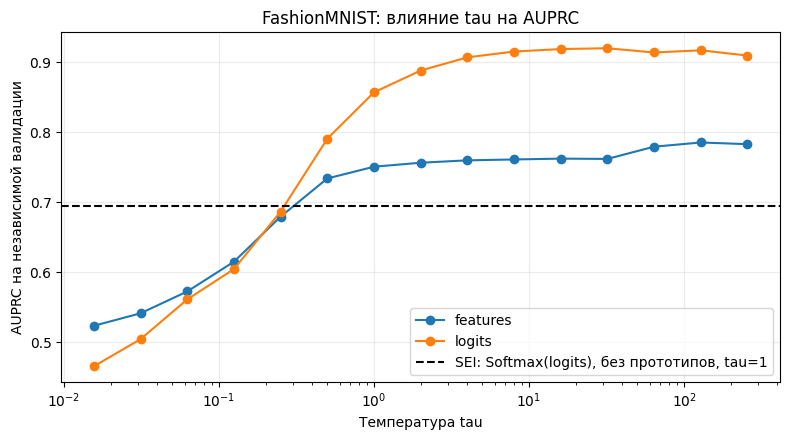

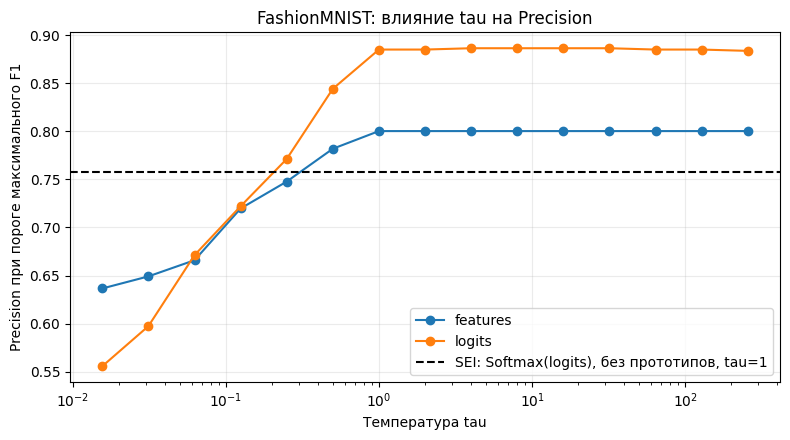

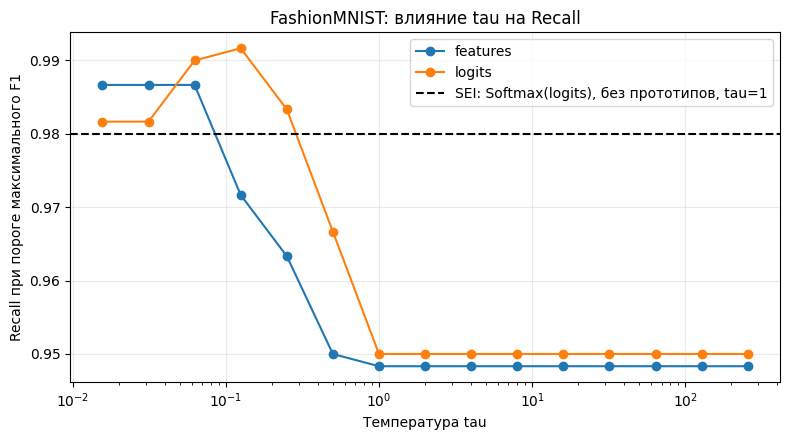

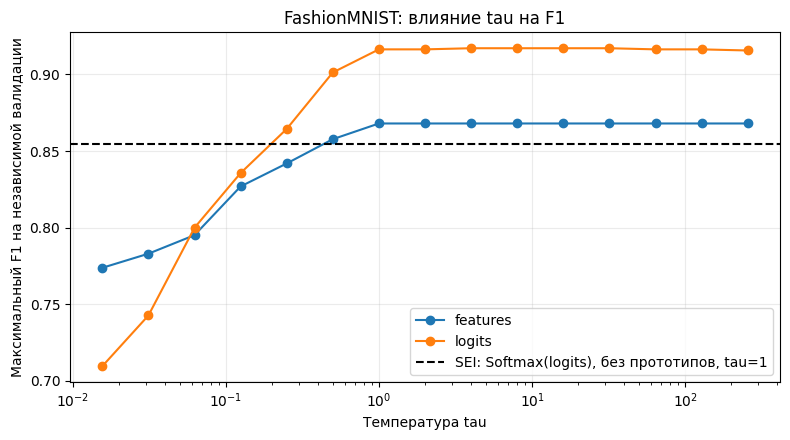

In [10]:
# 8.3 подбор tau на отделной выборке, 
# при этом не пересекается с X_train, 
# AUPRC обнаружения ошибок  
def load_val_subset(dataset_name, train_limit, val_limit):
    DatasetClass = datasets.MNIST if dataset_name.lower() == "mnist" else datasets.FashionMNIST
    data = DatasetClass(root=DATA_ROOT, train=True, download=True)

    if train_limit is None:
        raise ValueError("Для отдельной валидации выборки задайте TRAIN_LIMIT")

    generator = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(data.targets), generator=generator)
    val_start = train_limit
    val_end = val_start + val_limit
    if val_end > len(data.targets):
        raise ValueError("TRAIN_LIMIT + VAL_LIMIT превышает размер исходной обучающей выборки")

    ids = perm[val_start:val_end]
    X = data.data[ids].float().unsqueeze(1) / 255.0
    y = torch.as_tensor(data.targets, dtype=torch.long)[ids]
    return X, y


def best_f1_operating_point(y_true_binary, score):
    """Возвращает Precision, Recall, F1 в точке порога, максимизирующей F1 на валидации"""
    
    precision, recall, thresholds = precision_recall_curve(y_true_binary, score)
    f1_values = 2.0 * precision * recall / np.maximum(precision + recall, EPS)
  
    best_idx = int(np.nanargmax(f1_values))
    threshold = thresholds[best_idx] if best_idx < len(thresholds) else np.inf
  
    return {
        "Precision": float(precision[best_idx]),
        "Recall": float(recall[best_idx]),
        "F1": float(f1_values[best_idx]),
        "F1 threshold": float(threshold),
    }


def tune_tau(X_fit, y_fit_clean, X_val, y_val_clean, noise_rate=VAL_NOISE_RATE):
    rows = []
    reference_rows = []
    num_classes_local = int(max(y_fit_clean.max().item(), y_val_clean.max().item()) + 1)

    for tuning_seed in TAU_TUNING_SEEDS:
        print(f"Подбор tau для seed={tuning_seed}")

        y_fit_noisy, _ = make_noisy_labels(
            X_fit, y_fit_clean, "symmetric", noise_rate, seed=tuning_seed + 700
        )

        y_val_noisy, val_mask = make_noisy_labels(
            X_val, y_val_clean, "symmetric", noise_rate, seed=tuning_seed + 1700
        )

        y_val_np = y_val_noisy.numpy()
        val_mask_np = val_mask.astype(int)

        traj = train_with_trajectory(
            X_fit, y_fit_noisy, num_classes_local, epochs=SEI_EPOCHS,
            seed=tuning_seed + 2700, eval_X=X_val
        )

        # софтмакс от логитов, без прототипов
        #!!! в softmax_np(logits)  tau=1
        reference_probabilities = softmax_np(traj["logits"])
        reference_score = sei_score(reference_probabilities, y_val_np)
        reference_ap = average_precision_score(val_mask_np, reference_score)
        reference_point = best_f1_operating_point(val_mask_np, reference_score)
        reference_rows.append({"seed": tuning_seed, "AUPRC": reference_ap, **reference_point})

        for emb in ["features", "logits"]:
            fit_trajectory = traj[f"reference_{emb}"]
    
            for tau in TAU_GRID:
                probabilities = prototype_probs_external(
                    traj[emb], fit_trajectory, y_fit_noisy.numpy(), num_classes_local, tau
                )
    
                score = sei_score(probabilities, y_val_np)
                ap = average_precision_score(val_mask_np, score)
                prf = best_f1_operating_point(val_mask_np, score)
                rows.append({
                    "seed": tuning_seed, "emb": emb, "tau": tau,
                    "AUPRC": float(ap), **prf,
                })

    runs = pd.DataFrame(rows)
    tuning_df = (runs.groupby(["emb", "tau"], as_index=False)
                 [["AUPRC", "Precision", "Recall", "F1", "F1 threshold"]].mean())
    best_rows = tuning_df.loc[tuning_df.groupby("emb")["AUPRC"].idxmax()]
    tau_by_embedding = {row.emb: float(row.tau) for row in best_rows.itertuples()}
    
    best_tau = {
        (emb, loo): tau_by_embedding[emb]
        for emb in ["features", "logits"]
        for loo in [False, True]
    }

    reference_runs = pd.DataFrame(reference_rows)
    reference_metrics = reference_runs[["AUPRC", "Precision", "Recall", "F1"]].mean().to_dict()

    return tuning_df, best_tau, reference_metrics, runs, reference_runs


X_val, y_val_clean = load_val_subset(DATASET_NAME, TRAIN_LIMIT, VAL_LIMIT)
tuning_df, best_tau, reference_metrics, tau_tuning_runs, tau_reference_runs = tune_tau(
    X_train, y_true, X_val, y_val_clean
)

print("Базовый SEI: Softmax(logits), без прототипов, tau=1:")
print({k: round(v, 4) for k, v in reference_metrics.items()})
print("Оптимальные tau по AUPRC:", best_tau)
display(tuning_df.round(4))

#4 отдельных графика: ранжирование и P/R/F1 в точке максимального F1
metric_plots = [
    ("AUPRC", "AUPRC на независимой валидации"),
    ("Precision", "Precision при пороге максимального F1"),
    ("Recall", "Recall при пороге максимального F1"),
    ("F1", "Максимальный F1 на независимой валидации"),
]

for metric, y_label in metric_plots:
    plt.figure(figsize=(8, 4.5))
    for emb, group in tuning_df.groupby("emb"):
        group = group.sort_values("tau")
        plt.plot(group["tau"], group[metric], marker="o", label=emb)

    plt.axhline(
        reference_metrics[metric], color="black", linestyle="--",
        label="SEI: Softmax(logits), без прототипов, tau=1"
    )
    
    plt.xscale("log")
    plt.xlabel("Температура tau")
    plt.ylabel(y_label)
    plt.title(f"{DATASET_NAME}: влияние tau на {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"tau_validation_{metric.lower()}.png"), dpi=180)
    plt.show()

tuning_df.to_csv(os.path.join(OUTPUT_DIR, "results_tau_tuning.csv"), index=False)
tau_tuning_runs.to_csv(os.path.join(OUTPUT_DIR, "results_tau_tuning_runs.csv"), index=False)
tau_reference_runs.to_csv(os.path.join(OUTPUT_DIR, "results_tau_reference_metrics.csv"), index=False)


обычный sei logits отличается от logits тем, что у обычного: tau = 1, нет операции косинусного сходства

## Этап 8.4. Сравнение вариантов SEI на искусственном шуме

In [11]:
# 8.4 СРАВНЕНИЕ: SEI, SEI на прототипах и старые методы
# tau из 8.3
replicate_cache = {}
auxiliary_threshold_rows = []
auxiliary_diagnostics = {}


def run_one(X_tr, y_tr_clean, noise_type, rate, seed):
    y_noisy_l, mask = make_noisy_labels(
        X_tr, y_tr_clean, noise_type, rate, seed=seed
    )
    mask_i = mask.astype(int)
    y_np = y_noisy_l.numpy()

    traj = train_with_trajectory(
        X_tr, y_noisy_l, NUM_CLASSES, SEI_EPOCHS, seed=seed
    )
    scores = compute_sei_scores(traj, y_np, best_tau)

    if RUN_AUXILIARY_CLASS:
        anchor_mask = make_auxiliary_anchor_mask(
            n_samples=len(y_noisy_l), num_classes=NUM_CLASSES,
            seed=seed + AUX_SEED_OFFSET,
        )
        for emb in ["features", "logits"]:
            tau_aux = AUX_TAU_BY_EMBEDDING[emb]
            for loo_aux in AUX_LOO_OPTIONS:
                aux_result = auxiliary_class_sei(
                    traj[emb], y_np, NUM_CLASSES, tau_aux, anchor_mask, loo=loo_aux
                )
                method_name = f"Auxiliary Class [{emb}{', LOO' if loo_aux else ''}]"
                scores[method_name] = aux_result["suspicion_score"]

                threshold_metrics = evaluate_auxiliary_threshold(mask_i, aux_result)
                auxiliary_threshold_rows.append({
                    "Датасет": DATASET_NAME,
                    "noise_type": noise_type,
                    "noise_rate": rate,
                    "seed": seed,
                    "Представление": emb,
                    "LOO": loo_aux,
                    "tau": tau_aux,
                    **threshold_metrics,
                })

                # Сохраняем распределение только для основного запуска и LOO=True.
                if (noise_type == NOISE_TYPE and rate == NOISE_RATE
                        and seed == EVAL_SEEDS[0] and loo_aux):
                    auxiliary_diagnostics[emb] = {
                        "result": aux_result,
                        "noise_mask": mask_i.copy(),
                    }

    if RUN_LEGACY_OOF:
        # Старый OOF pipeline оставлен для возможности вернуться к сравнению.
        if (seed == EVAL_SEEDS[0]
                and noise_type == NOISE_TYPE
                and rate == NOISE_RATE
                and oof_probs is not None
                and np.array_equal(y_noisy_l.numpy(), y_noisy.numpy())):
            oof, dyn, knn, ens = oof_probs, dynamic_score, knn_score, ensemble_score
        else:
            oof, dyn, knn, ens = get_oof_signals(
                X_tr, y_noisy_l, num_classes=NUM_CLASSES, folds=FOLDS,
                ensemble_size=ENSEMBLE_SIZE, epochs=OOF_EPOCHS,
                seed=seed
            )

        base, _ = make_score_methods(y_noisy_l, oof, dyn, knn, ens)
        scores["Cleanlab"] = base["Cleanlab"]
        scores["Combined (D+K+E)"] = base["Combined (D+K+E)"]
        replicate_cache[seed] = {
            "y_noisy": y_noisy_l.clone(), "noise_mask": mask_i.copy(),
            "oof_probs": oof, "methods": base,
        }
    else:
        replicate_cache[seed] = {
            "y_noisy": y_noisy_l.clone(), "noise_mask": mask_i.copy(),
            "sei_scores": scores,
        }

    return [
        dict(evaluate_score(name, score, mask_i),
             noise_type=noise_type, rate=rate, seed=seed)
        for name, score in scores.items()
    ]


all_rows = []
for noise_type in EVAL_NOISE_TYPES:
    for rate in EVAL_NOISE_RATES:
        for seed in EVAL_SEEDS:
            print(f"--- {noise_type}, шум {rate:.0%}, seed {seed}")
            all_rows += run_one(X_train, y_true, noise_type, rate, seed)

sei_results = pd.DataFrame(all_rows)
sei_results.to_csv(os.path.join(OUTPUT_DIR, "results_sei_detection.csv"), index=False)

summary = (sei_results.groupby(["noise_type", "rate", "Метод"], as_index=False)
           [["Precision@K", "Average Precision", "ROC-AUC"]].mean())

print("Результаты обнаружения ошибок для seed=42:")
display(summary.sort_values("Average Precision", ascending=False).round(3))

--- symmetric, шум 20%, seed 42
Результаты обнаружения ошибок для seed=42:


,noise_type,rate,Метод,Precision@K,Average Precision,ROC-AUC
11,symmetric,0.2,SEI прототипы [logits],0.925,0.944,0.989
10,symmetric,0.2,"SEI прототипы [logits, LOO]",0.925,0.944,0.989
7,symmetric,0.2,SEI (softmax логитов),0.834,0.799,0.968
9,symmetric,0.2,SEI прототипы [features],0.793,0.790,0.961
8,symmetric,0.2,"SEI прототипы [features, LOO]",0.792,0.789,0.961
3,symmetric,0.2,Auxiliary Class [logits],0.699,0.705,0.944
2,symmetric,0.2,"Auxiliary Class [logits, LOO]",0.699,0.704,0.944
5,symmetric,0.2,SE@last (softmax),0.763,0.686,0.929
6,symmetric,0.2,SE@middle (softmax),0.710,0.621,0.929
1,symmetric,0.2,Auxiliary Class [features],0.607,0.609,0.916


## Этап 8.5. Auxiliary Class Threshold - адаптация к обычной CNN

В статье используется формула:

$$
N_{aux}=\frac{N}{K+1},
$$

где $N$ - количество обучающих изображений, $K$ - число настоящих классов. Для Fashion-MNIST при $N=50000$ и $K=10$:

$$
N_{aux}=\frac{50000}{11}\approx4545.
$$

Изображения выбираются случайно без возвращения. Их исходные наблюдаемые метки заменяются дополнительной меткой $K$.

### адаптация механизма к CNN 

реализована прототипная адаптация:

1) CNN обучается как обычно на $K$ исходных классах и наблюдаемых (возможно ошибочных) метках. Архитектура CNN не меняется: последний слой выдаёт $K$ логитов
2) После обучения на каждой эпохе берётся `features` или `logits`
3) Для $K$ настоящих классов строятся прототипы по наблюдаемым меткам, а для дополнительного класса - средний вектор случайно выбранных  изображений(anchor-изображения)
4) Получается $K+1$ прототипов, сходства изображения с ними переводятся в вероятности через Softmax с параметрмо $\tau$
5) Для anchor-изображений в формуле SEI используется дополнительная метка $K$

дополнительный класс существует на этапе построения прототипов и вычисления вероятностей,а не как дополнительный обучаемый выходной нейрон CNN

### Формулы прототипной адаптации

Пусть $v_i^{(e)}$ вектор `features` или `logits` изображения $i$ на эпохе $e$. Для класса $c$ прототип равен:

$$
\mu_c^{(e)}=\frac{1}{N_c}\sum_{i:\tilde y_i=c}v_i^{(e)},
$$

где $\tilde y_i=K$ для anchor-объектов, а для остальных $\tilde y_i$ равна наблюдаемой метке.

Сходство с прототипом:

$$
s_{i,c}^{(e)}=\frac{v_i^{(e)}\cdot\mu_c^{(e)}}{\|v_i^{(e)}\|_2\|\mu_c^{(e)}\|_2+\varepsilon}.
$$

Вероятности по $K+1$ классам:

$$
P_{i,c}^{(e)}=\frac{\exp(s_{i,c}^{(e)}/\tau)}{\sum_{j=0}^{K}\exp(s_{i,j}^{(e)}/\tau)}.
$$

Энтропия и знаковая энтропия:

$$
H_i^{(e)}=-\sum_{c=0}^{K}P_{i,c}^{(e)}\ln(P_{i,c}^{(e)}+\varepsilon),
$$

$$
SE_i^{(e)}=\begin{cases}
+H_i^{(e)}, & \arg\max_c P_{i,c}^{(e)}=\tilde y_i,\\
-H_i^{(e)}, & \arg\max_c P_{i,c}^{(e)}\ne\tilde y_i.
\end{cases}
$$

Итоговая оценка:

$$
SEI_i=\sum_{e=1}^{E}SE_i^{(e)}.
$$

Для дополнительного класса вычисляется средний SEI:

$$
T_{aux}=\frac{1}{N_{aux}}\sum_{i\in A}SEI_i,
$$

где $A$ - множество anchor-объектов. Объект помечается как подозрительный, если:

$$
\boxed{SEI_i<T_{aux}.}
$$

В коде используется рейтинг `score = -SEI`, поэтому эквивалентное правило имеет вид `score > -T_aux`.


Порог $T_{aux}$ рассчитывается только по SEI anchor-объектов. Истинная маска искусственного шума и фактическая доля испорченных меток не участвуют ни в выборе anchor-объектов, ни в расчёте порога. После фиксации порога истинная маска используется только для исследовательской оценки Precision, Recall, F1, AUPRC и ROC-AUC



## Этап 8.5 Auxiliary Class



,Датасет,noise_type,noise_rate,seed,Представление,LOO,tau,Precision,Recall,F1,AUPRC,ROC-AUC,Threshold (SEI),Auxiliary count,Flagged count,Flagged fraction,TP,FP,FN,TN
0,FashionMNIST,symmetric,0.2,42,features,False,256.0,0.6194,0.9516,0.7504,0.6094,0.9164,-239.3780,4545,15364,0.3073,9516,5848,484,34152
1,FashionMNIST,symmetric,0.2,42,features,True,256.0,0.6193,0.9516,0.7503,0.6090,0.9163,-239.3843,4545,15365,0.3073,9516,5849,484,34151
2,FashionMNIST,symmetric,0.2,42,logits,False,32.0,0.6840,0.9289,0.7879,0.7046,0.9436,-239.4601,4545,13580,0.2716,9289,4291,711,35709
3,FashionMNIST,symmetric,0.2,42,logits,True,32.0,0.6840,0.9289,0.7879,0.7042,0.9436,-239.4622,4545,13580,0.2716,9289,4291,711,35709


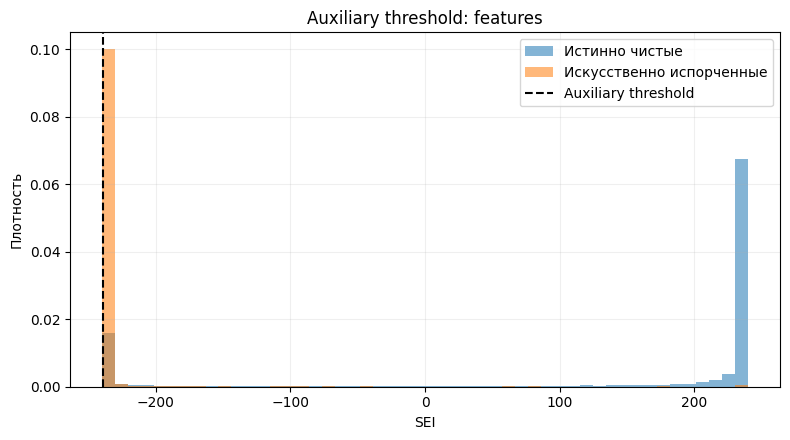

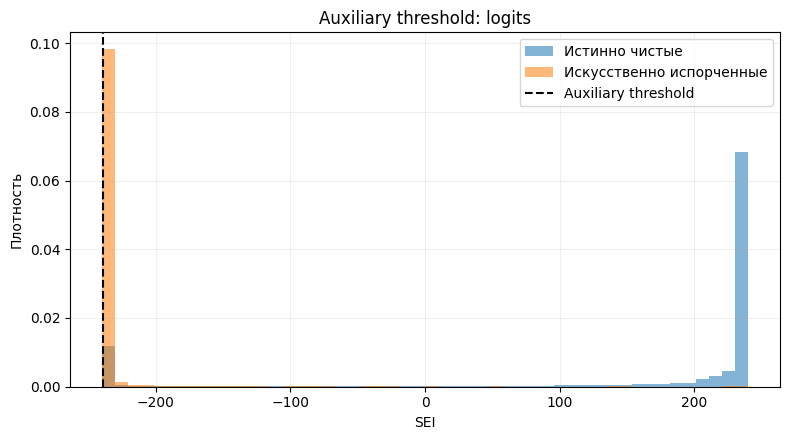

In [ ]:
# 8.5 Запуск Auxiliary Class Threshold на основной выборке
if RUN_AUXILIARY_CLASS:
    if not auxiliary_threshold_rows:
        print("Auxiliary Class не запускался: проверьте EVAL_SEEDS / этап 8.4")
    else:
        auxiliary_threshold_df = pd.DataFrame(auxiliary_threshold_rows)
        display(auxiliary_threshold_df.round(4))
        auxiliary_threshold_df.to_csv(
            os.path.join(OUTPUT_DIR, "results_auxiliary_threshold_fashion.csv"), index=False
        )

        # Для основного Fashion-MNIST запуска сохраняем графики распределений SEI
        for diagnostic_name, diagnostic in auxiliary_diagnostics.items():
            plot_auxiliary_threshold_diagnostic(
                diagnostic["result"], diagnostic["noise_mask"],
                title=f"Auxiliary threshold: {diagnostic_name}",
                output_path=os.path.join(
                    OUTPUT_DIR,
                    "auxiliary_threshold_" + diagnostic_name.replace(" ", "_").replace("/", "-") + ".png"
                ),
            )
else:
    print("Auxiliary Class отключён: RUN_AUXILIARY_CLASS=False")


## Этап 8.6. Запуск SEI и Auxiliary Class на CIFAR-10N

In [13]:
# 8.6 проверка SEI на CIFAR-10N без OOF-методов
if RUN_SEI_CIFAR10N:
    d = load_cifar10n_data(
        label_type=CIFAR10N_LABEL_TYPE,
        train_limit=CIFAR10N_TRAIN_LIMIT,
        test_limit=CIFAR10N_TEST_LIMIT,
    )

    y_c = d["y_noisy"].numpy()
    traj_c = train_with_trajectory(
        d["X_train"], d["y_noisy"], 10, SEI_EPOCHS, seed=SEED + 500
    )

    scores_c = compute_sei_scores(traj_c, y_c, best_tau)
    cifar_noise_mask = (d["y_noisy"].numpy() != d["y_clean"].numpy()).astype(int)

    if RUN_AUXILIARY_CLASS and RUN_AUXILIARY_CIFAR10N:
        cifar_auxiliary_rows = []
        anchor_mask_c = make_auxiliary_anchor_mask(
            n_samples=len(y_c), num_classes=10, seed=SEED + 500 + AUX_SEED_OFFSET
        )
        for emb in ["features", "logits"]:
            for loo_aux in AUX_LOO_OPTIONS:
                aux_result_c = auxiliary_class_sei(
                    traj_c[emb], y_c, 10, AUX_TAU_BY_EMBEDDING[emb],
                    anchor_mask_c, loo=loo_aux
                )
                method_name_c = f"Auxiliary Class [{emb}{', LOO' if loo_aux else ''}]"
                scores_c[method_name_c] = aux_result_c["suspicion_score"]
                metrics_c = evaluate_auxiliary_threshold(cifar_noise_mask, aux_result_c)
                cifar_auxiliary_rows.append({
                    "Датасет": "CIFAR-10N",
                    "label_type": CIFAR10N_LABEL_TYPE,
                    "Представление": emb,
                    "LOO": loo_aux,
                    "tau": AUX_TAU_BY_EMBEDDING[emb],
                    **metrics_c,
                })

        cifar_auxiliary_df = pd.DataFrame(cifar_auxiliary_rows)
        display(cifar_auxiliary_df.round(4))
        cifar_auxiliary_df.to_csv(
            os.path.join(OUTPUT_DIR, "results_auxiliary_threshold_cifar10n.csv"), index=False
        )

    cifar_sei_results = (
        pd.DataFrame([
            evaluate_score(name, score, cifar_noise_mask)
            for name, score in scores_c.items()
        ])
        .sort_values("Average Precision", ascending=False)
        .reset_index(drop=True)
    )

    display(cifar_sei_results)
    cifar_sei_results.to_csv(
        os.path.join(OUTPUT_DIR, "results_sei_cifar10n_only.csv"), index=False
    )
    
else:
    print("Проверка SEI на CIFAR-10N пропущена: RUN_SEI_CIFAR10N=False")


,Датасет,label_type,Представление,LOO,tau,Precision,Recall,F1,AUPRC,ROC-AUC,Threshold (SEI),Auxiliary count,Flagged count,Flagged fraction,TP,FP,FN,TN
0,CIFAR-10N,aggre_label,features,False,256.0,0.2121,0.6917,0.3247,0.2030,0.7728,-222.2535,4545,14691,0.2938,3116,11575,1389,33920
1,CIFAR-10N,aggre_label,features,True,256.0,0.2118,0.6919,0.3243,0.2027,0.7728,-222.3326,4545,14719,0.2944,3117,11602,1388,33893
2,CIFAR-10N,aggre_label,logits,False,32.0,0.2432,0.5820,0.3431,0.2408,0.7892,-227.7564,4545,10781,0.2156,2622,8159,1883,37336
3,CIFAR-10N,aggre_label,logits,True,32.0,0.2431,0.5822,0.3430,0.2407,0.7892,-227.7860,4545,10789,0.2158,2623,8166,1882,37329


,Метод,Precision@K,Average Precision,ROC-AUC
0,SEI (softmax логитов),0.374251,0.326805,0.809125
1,SEI прототипы [logits],0.390677,0.303309,0.824605
2,"SEI прототипы [logits, LOO]",0.390233,0.303102,0.824583
3,SEI прототипы [features],0.284795,0.251532,0.807021
4,"SEI прототипы [features, LOO]",0.276360,0.250414,0.806598
5,Auxiliary Class [logits],0.278801,0.240845,0.789199
6,"Auxiliary Class [logits, LOO]",0.278801,0.240655,0.789202
7,SE@last (softmax),0.275472,0.226516,0.690157
8,SE@middle (softmax),0.242619,0.211358,0.719979
9,Auxiliary Class [features],0.221310,0.203043,0.772797
